In [2]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/UPI_Fraud_Project")

for notebook in root.rglob("*.ipynb"):
    try:
        with open(notebook, "r", encoding="utf-8") as f:
            data = json.load(f)

        for i, cell in enumerate(data.get("cells", [])):
            source = "".join(cell.get("source", []))
            if any(term in source.lower() for term in [
                "randomforestclassifier",
                "random forest",
                "randomforest"
            ]):
                print(f"\nNotebook: {notebook}")
                print(f"Cell: {i}")
                print(source[:1200])
    except Exception as e:
        print(f"Could not read {notebook.name}: {e}")

In [3]:
from pathlib import Path

root = Path("/content/drive/MyDrive/UPI_Fraud_Project")

for folder in [root, root / "results", root / "results" / "Traditional_ML"]:
    print(f"\n--- {folder} ---")
    if folder.exists():
        for item in sorted(folder.iterdir()):
            print(item.name)
    else:
        print("Folder not found")


--- /content/drive/MyDrive/UPI_Fraud_Project ---
Folder not found

--- /content/drive/MyDrive/UPI_Fraud_Project/results ---
Folder not found

--- /content/drive/MyDrive/UPI_Fraud_Project/results/Traditional_ML ---
Folder not found


In [4]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

print("MyDrive accessible:", root.exists())

if root.exists():
    for p in root.iterdir():
        if "UPI" in p.name.upper() or "FRAUD" in p.name.upper():
            print("Found:", p)
            if p.is_dir():
                print("Contents:")
                for item in p.iterdir():
                    print("  ", item.name)

MyDrive accessible: False


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
from pathlib import Path

root = Path("/content/drive/MyDrive")
print("MyDrive accessible:", root.exists())

if root.exists():
    for p in root.iterdir():
        if "UPI" in p.name.upper() or "FRAUD" in p.name.upper():
            print("Found:", p)

MyDrive accessible: True
Found: /content/drive/MyDrive/UPI_Fraud_Project


In [7]:
from pathlib import Path

root = Path("/content/drive/MyDrive/UPI_Fraud_Project")

print("Project folder exists:", root.exists())

for p in sorted(root.rglob("*")):
    if p.is_file() and (
        p.suffix.lower() in [".ipynb", ".csv", ".joblib", ".pkl", ".md"]
        or "forest" in p.name.lower()
        or "random" in p.name.lower()
    ):
        print(p.relative_to(root))

Project folder exists: True
explainability_deliverables/xgboost_temporal_model.joblib
explainability_deliverables/xgboost_temporal_preprocessor.joblib
gat_graphs/gat_test_probabilities.csv


In [8]:
from pathlib import Path

root = Path("/content/drive/MyDrive/UPI_Fraud_Project")

for p in sorted(root.rglob("*")):
    if p.is_file() and p.suffix.lower() in [".csv", ".ipynb"]:
        print(p.relative_to(root))

gat_graphs/gat_test_probabilities.csv


In [9]:
from pathlib import Path

dataset = Path(
    "/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv"
)

print("Dataset exists:", dataset.exists())

if dataset.exists():
    print("Dataset size (GB):", round(dataset.stat().st_size / (1024**3), 2))

Dataset exists: True
Dataset size (GB): 0.46


In [10]:
import joblib
import pandas as pd
from pathlib import Path

project = Path("/content/drive/MyDrive/UPI_Fraud_Project")
model_path = project / "explainability_deliverables/xgboost_temporal_model.joblib"
prep_path = project / "explainability_deliverables/xgboost_temporal_preprocessor.joblib"
data_path = Path("/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv")

# 1. Check dataset columns without loading the full dataset into RAM
print("DATASET COLUMNS")
print(pd.read_csv(data_path, nrows=5).columns.tolist())

# 2. Inspect the existing saved XGBoost artifacts
model = joblib.load(model_path)
preprocessor = joblib.load(prep_path)

print("\nXGBoost model:", type(model).__name__)
print("Expected input features:", getattr(model, "n_features_in_", "Not available"))
print("Preprocessor:", type(preprocessor).__name__)

print("\nPREPROCESSOR DETAILS")
if hasattr(preprocessor, "transformers_"):
    for name, transformer, columns in preprocessor.transformers_:
        print(f"\nTransformer: {name}")
        print("Columns:", columns)
        print("Transformer type:", type(transformer).__name__)

if hasattr(preprocessor, "feature_names_in_"):
    print("\nOriginal input feature names:")
    print(preprocessor.feature_names_in_.tolist())

if hasattr(preprocessor, "get_feature_names_out"):
    try:
        print("\nTransformed feature names:")
        print(preprocessor.get_feature_names_out().tolist())
    except Exception as e:
        print("Could not retrieve transformed names:", str(e))

DATASET COLUMNS
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

XGBoost model: XGBClassifier
Expected input features: 11
Preprocessor: ColumnTransformer

PREPROCESSOR DETAILS

Transformer: num
Columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Transformer type: StandardScaler

Transformer: cat
Columns: ['type']
Transformer type: OneHotEncoder

Original input feature names:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

Transformed feature names:
['num__step', 'num__amount', 'num__oldbalanceOrg', 'num__newbalanceOrig', 'num__oldbalanceDest', 'num__newbalanceDest', 'cat__type_CASH_IN', 'cat__type_CASH_OUT', 'cat__type_DEBIT', 'cat__type_PAYMENT', 'cat__type_TRANSFER']


In [11]:

from pathlib import Path
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

PROJECT = Path("/content/drive/MyDrive/UPI_Fraud_Project")
DATA_PATH = Path("/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv")
OUT_DIR = PROJECT / "random_forest_deliverables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATA_PATH.exists())
print("Output directory:", OUT_DIR)


Dataset exists: True
Output directory: /content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables


In [12]:

from pathlib import Path
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

PROJECT = Path("/content/drive/MyDrive/UPI_Fraud_Project")
DATA_PATH = Path("/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv")
OUT_DIR = PROJECT / "random_forest_deliverables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATA_PATH.exists())
print("Output directory:", OUT_DIR)


Dataset exists: True
Output directory: /content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables


In [13]:

import pandas as pd

DATA_PATH = "/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Step range:", df["step"].min(), "-", df["step"].max())

splits = {
    "Train": (280, 319),
    "Validation": (320, 354),
    "Test": (355, 743),
}

for name, (start, end) in splits.items():
    part = df[df["step"].between(start, end)]
    print(
        f"{name}: transactions={len(part):,}, "
        f"fraud={int(part['isFraud'].sum()):,}, "
        f"steps={start}-{end}"
    )

del df


Dataset shape: (6362620, 11)
Step range: 1 - 743
Train: transactions=621,909, fraud=424, steps=280-319
Validation: transactions=680,323, fraud=360, steps=320-354
Test: transactions=1,293,523, fraud=4,258, steps=355-743


In [14]:

import gc
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

PROJECT = Path("/content/drive/MyDrive/UPI_Fraud_Project")
OUT_DIR = PROJECT / "random_forest_deliverables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = "/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)

numeric_features = [
    "step", "amount", "oldbalanceOrg",
    "newbalanceOrig", "oldbalanceDest", "newbalanceDest"
]
categorical_features = ["type"]
features = numeric_features + categorical_features
target = "isFraud"

# Create chronological splits
train_df = df[df["step"].between(280, 319)]
val_df = df[df["step"].between(320, 354)]
test_df = df[df["step"].between(355, 743)]

X_train_raw = train_df[features]
y_train = train_df[target].to_numpy()

X_val_raw = val_df[features]
y_val = val_df[target].to_numpy()

X_test_raw = test_df[features]
y_test = test_df[target].to_numpy()

# Preprocessing: fit on training data only
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

print("Train matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

# Start with 100 trees to keep training more manageable
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

rf_model.fit(X_train, y_train)

# Save immediately after training
joblib.dump(rf_model, OUT_DIR / "random_forest_temporal_model.joblib")
joblib.dump(preprocessor, OUT_DIR / "random_forest_temporal_preprocessor.joblib")

print("\nTraining complete. Model and preprocessor saved.")
print("Output folder:", OUT_DIR)


Train matrix: (621909, 11)
Validation matrix: (680323, 11)
Test matrix: (1293523, 11)


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   38.2s



Training complete. Model and preprocessor saved.
Output folder: /content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables


[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  1.4min finished


In [15]:

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict fraud probabilities on validation data
val_prob = rf_model.predict_proba(X_val)[:, 1]

rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (val_prob >= threshold).astype(int)
    rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "flagged_transactions": int(pred.sum()),
    })

threshold_df = pd.DataFrame(rows)

threshold_path = OUT_DIR / "rf_validation_threshold_results.csv"
threshold_df.to_csv(threshold_path, index=False)

display(threshold_df.round(4))

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print("Selected threshold:", BEST_THRESHOLD)
print("Validation F1:", round(float(best_row["f1"]), 4))
print("Saved:", threshold_path)


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    2.9s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    5.5s finished


,threshold,precision,recall,f1,flagged_transactions
0,0.10,0.0009,1.0000,0.0019,380231
1,0.15,0.0017,1.0000,0.0035,206207
2,0.20,0.0035,1.0000,0.0070,102265
3,0.25,0.0055,0.9889,0.0109,64741
4,0.30,0.0144,0.9667,0.0284,24115
5,0.35,0.0274,0.9250,0.0533,12145
6,0.40,0.0452,0.8750,0.0859,6971
7,0.45,0.0848,0.8333,0.1539,3539
8,0.50,0.2011,0.7861,0.3203,1407
9,0.55,0.4491,0.7472,0.5610,599


Selected threshold: 0.75
Validation F1: 0.7743
Saved: /content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables/rf_validation_threshold_results.csv


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    2.3s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    4.7s finished


{
  "model": "Random Forest",
  "split": "Temporal",
  "threshold": 0.75,
  "test_transactions": 1293523,
  "actual_fraud": 4258,
  "precision": 0.9976798143851509,
  "recall": 0.7069046500704557,
  "f1": 0.8274914089347079,
  "pr_auc": 0.828544443449248,
  "roc_auc": 0.992020276637205,
  "true_negative": 1289258,
  "false_positive": 7,
  "false_negative": 1248,
  "true_positive": 3010,
  "flagged_transactions": 3017
}


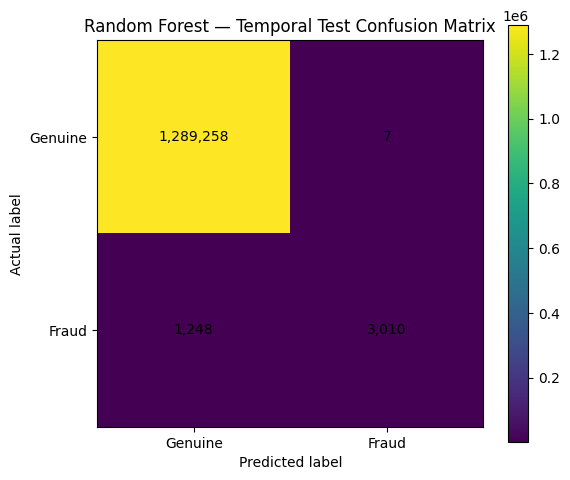


Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1289265
           1       1.00      0.71      0.83      4258

    accuracy                           1.00   1293523
   macro avg       1.00      0.85      0.91   1293523
weighted avg       1.00      1.00      1.00   1293523


Saved files:
/content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables/random_forest_temporal_results.csv
/content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables/rf_test_predictions.csv
/content/drive/MyDrive/UPI_Fraud_Project/random_forest_deliverables/rf_confusion_matrix.png


In [16]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Keep the validation-selected threshold fixed
threshold = BEST_THRESHOLD

# Predict on the untouched temporal test set
test_prob = rf_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype("int8")

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

results = {
    "model": "Random Forest",
    "split": "Temporal",
    "threshold": float(threshold),
    "test_transactions": int(len(y_test)),
    "actual_fraud": int(np.sum(y_test)),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "pr_auc": float(average_precision_score(y_test, test_prob)),
    "roc_auc": float(roc_auc_score(y_test, test_prob)),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
    "flagged_transactions": int(np.sum(test_pred)),
}

print(json.dumps(results, indent=2))

out_file = OUT_DIR / "random_forest_temporal_results.csv"
pd.DataFrame([results]).to_csv(out_file, index=False)

# Save per-transaction predictions for later analysis
pred_file = OUT_DIR / "rf_test_predictions.csv"
pd.DataFrame({
    "actual_label": y_test,
    "fraud_probability": test_prob,
    "predicted_label": test_pred,
}).to_csv(pred_file, index=False)

# Confusion matrix figure
cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_title("Random Forest — Temporal Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], ["Genuine", "Fraud"])
ax.set_yticks([0, 1], ["Genuine", "Fraud"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT_DIR / "rf_confusion_matrix.png", dpi=160)
plt.show()

print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))

print("\nSaved files:")
print(out_file)
print(pred_file)
print(OUT_DIR / "rf_confusion_matrix.png")


In [17]:

from pathlib import Path

for path in sorted(OUT_DIR.iterdir()):
    print(f"{'OK' if path.is_file() else 'FOLDER'}  {path.name}")


OK  random_forest_temporal_model.joblib
OK  random_forest_temporal_preprocessor.joblib
OK  random_forest_temporal_results.csv
OK  rf_confusion_matrix.png
OK  rf_test_predictions.csv
OK  rf_validation_threshold_results.csv
